In questo notebook inserisco i grafici relativi ai risultati sperimentali ottenuti tramite le sessioni di training e test delle politiche. 

Consiste in un riassunto e confronto dei contenutti dei notebook: "training_X_error_scratch" e "training_X_error_with_PPR"

In [154]:
import numpy as np
import matplotlib.pyplot as plt
from Function_Library import *
from Environments import *
from Agent_Torch import *

In [155]:
rolling_average_length = 500
# colori per grafici
colore_ddqn = 'C0'
colore_ppr = 'C3'
# font times new roman per i grafici
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'Times', 'DejaVu Serif', 'Computer Modern Roman']
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'

# Env X error 0.001

In [156]:
p_err = 0.001
faulty_qubit_lifetime = 1/p_err

per questo ambiente è stata addestrata solo una politica secondo paradigma DDQN tradizionale

In [157]:
run = 'DDQN_d5_p0.001_20251013-230503'
print(f'run: {run}')

run: DDQN_d5_p0.001_20251013-230503


In [158]:
# dati allenamento
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.001_20251013-230503\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime)}')


Contenuto di runs\DDQN_d5_p0.001_20251013-230503\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 10858.33


grafico lifetime vs timestep - DDQN_d5_p0.001_20251013-230503


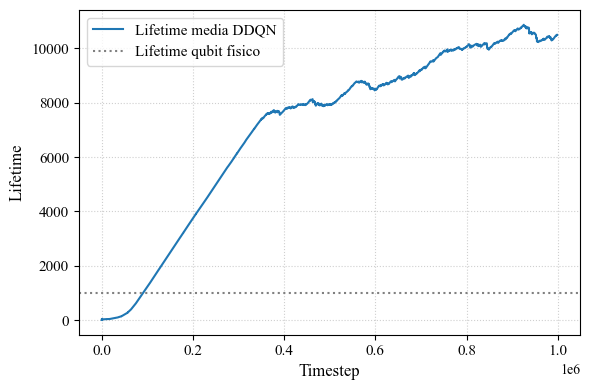

In [159]:
# avg_lifetime vs timestep
print(f'grafico lifetime vs timestep - {run}')
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(step, avg_lifetime, c=colore_ddqn, label='Lifetime media DDQN')
plt.axhline(y=faulty_qubit_lifetime, color='gray', linestyle=':', label='Lifetime qubit fisico')
ax.set_xlabel('Timestep', fontsize=12)
ax.set_ylabel('Lifetime', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('lifetime_timestep_p0.001.pdf', dpi=300, bbox_inches='tight')
plt.show()

grafico lifetime vs episode - DDQN_d5_p0.001_20251013-230503


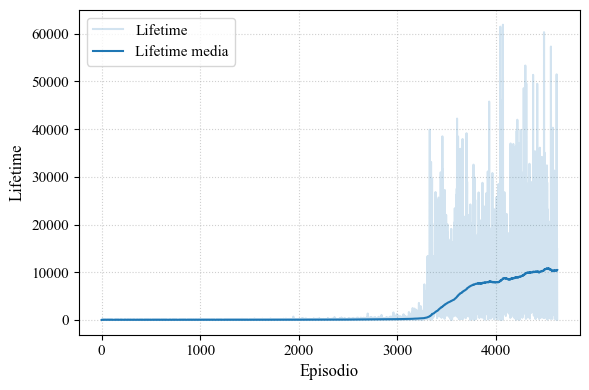

In [160]:
# lifetime vs episode
print(f'grafico lifetime vs episode - {run}')
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(episode, lifetime, label='Lifetime', alpha= 0.2, c=colore_ddqn)
ax.plot(episode, avg_lifetime, label=f'Lifetime media', c=colore_ddqn)
ax.set_ylabel('Lifetime', fontsize=12)
ax.set_xlabel('Episodio', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('lifetime_episode_p0.001.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [161]:
# dati test
test_path = r'test_runs\test_policy_DDQN_d5_p0.001_20251013-230503.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.std(test_lifetimes)
test_run = test_path.split('\\')[1]

print(f'lifetime media : {test_avg_lifetime}')


Contenuto di test_runs\test_policy_DDQN_d5_p0.001_20251013-230503.json estratto con successo:
lifetime media : 16723.355


istogramma relativo a test_policy_DDQN_d5_p0.001_20251013-230503.json


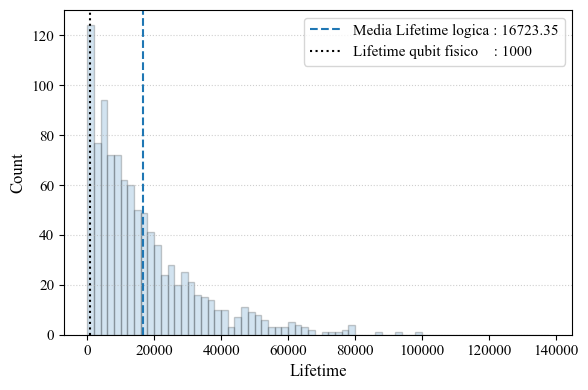

In [162]:
# istogramma
bins = np.arange(0, np.max(test_lifetimes), 2000)
print(f'istogramma relativo a {test_run}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.2, color=colore_ddqn)
ax.axvline(test_avg_lifetime, c=colore_ddqn, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ddqn_p0.001.pdf', dpi=300, bbox_inches='tight')
plt.show()



# Env X error 0.003

In [163]:
p_err = 0.003
faulty_qubit_lifetime = 1/p_err

In [164]:
run = 'DDQN_d5_p0.003_20251014-034106'
print(f'run: {run}')

run: DDQN_d5_p0.003_20251014-034106


In [165]:
# dati allenamento
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.003_20251014-034106\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime)}')


Contenuto di runs\DDQN_d5_p0.003_20251014-034106\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 1654.43


In [166]:
run_ppr = 'DDQN_PPR_d5_p0.003_20251017-042142'
print(f'run: {run_ppr}')

run: DDQN_PPR_d5_p0.003_20251017-042142


In [167]:
# dati allenamento ppr
# estrazione log di allenamento 
TRAINING_LOG_PATH_ppr = r'runs\DDQN_PPR_d5_p0.003_20251017-042142\training_history.json'
training_history_ppr = load_history(TRAINING_LOG_PATH_ppr)
step_ppr = np.array([log_data['step'] for log_data in training_history_ppr])
episode_ppr = np.array([log_data['episode'] for log_data in training_history_ppr])
reward_ppr = np.array([log_data['episode_reward'] for log_data in training_history_ppr])
avg_reward_ppr  = np.array([log_data['reward_mean'] for log_data in training_history_ppr])
lifetime_ppr = np.array([log_data['episode_lifetime'] for log_data in training_history_ppr])
avg_lifetime_ppr = np.array( [log_data['lifetime_mean'] for log_data in training_history_ppr])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history_ppr])


print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime_ppr)}')

Contenuto di runs\DDQN_PPR_d5_p0.003_20251017-042142\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 1663.36


grafico lifetime vs timestep - DDQN_d5_p0.003_20251014-034106 e DDQN_PPR_d5_p0.003_20251017-042142


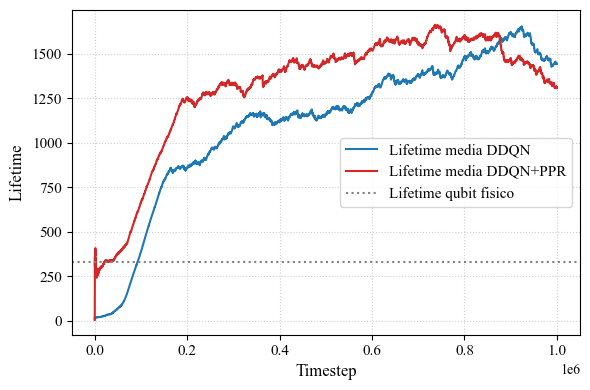

In [168]:
# avg_lifetime vs timestep
print(f'grafico lifetime vs timestep - {run} e {run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(step, avg_lifetime, c=colore_ddqn, label='Lifetime media DDQN')
ax.plot(step_ppr, avg_lifetime_ppr, c=colore_ppr, label='Lifetime media DDQN+PPR')
plt.axhline(y=faulty_qubit_lifetime, color='gray', linestyle=':', label='Lifetime qubit fisico')
ax.set_xlabel('Timestep', fontsize=12)
ax.set_ylabel('Lifetime', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('lifetime_timestep_p0.003.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafico policy riusata vs episode - DDQN_PPR_d5_p0.003_20251017-042142


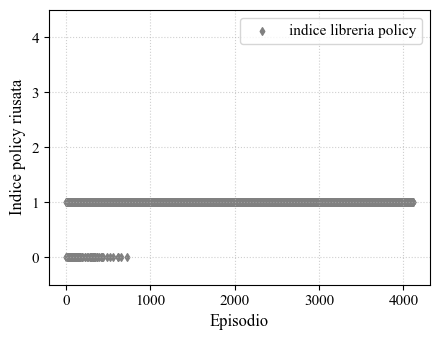

In [169]:
# reused policy vs episode
print(f'grafico policy riusata vs episode - {run_ppr}')
fig, ax = plt.subplots(figsize=(4.5,3.5))
ax.scatter(episode_ppr, index_k, c='grey', marker='d', s=15, label='indice libreria policy')
ax.set_xlabel('Episodio', fontsize=12)
ax.set_ylabel('Indice policy riusata', fontsize=12)
ax.set_yticks([ 0, 1, 2, 3, 4])
ax.set_ylim(bottom=-0.5, top=4.5)
ax.grid(True, linestyle=':', alpha=0.6)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('policy_reuse_episode_p0.003.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafici lifetime vs episodio - DDQN_d5_p0.003_20251014-034106 e DDQN_PPR_d5_p0.003_20251017-042142


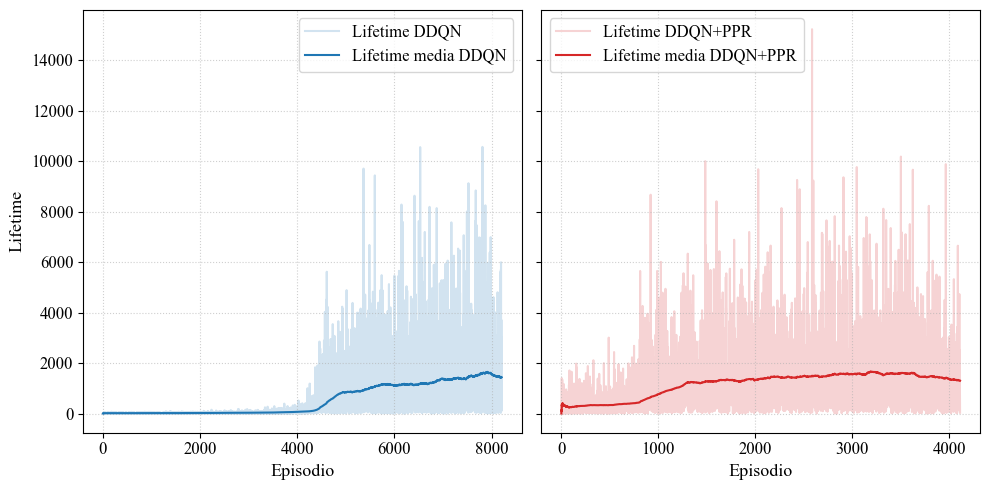

In [170]:
# lifetime vs episodio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True) 
# sharey=True assicura che entrambi gli assi Y abbiano la stessa scala 
print(f'grafici lifetime vs episodio - {run} e {run_ppr}')

ax1.plot(episode, lifetime, label='Lifetime DDQN', alpha=0.2, c=colore_ddqn, zorder=1)
ax1.plot(episode, avg_lifetime, label=f'Lifetime media DDQN', c=colore_ddqn, zorder=2) # zorder=2 per assicurare che la media sia sopra il rumore
ax1.set_xlabel('Episodio', fontsize=13)
ax1.set_ylabel('Lifetime', fontsize=13)
ax1.legend(fontsize=12)
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(episode_ppr, lifetime_ppr, label='Lifetime DDQN+PPR', alpha=0.2, c=colore_ppr, zorder=1)
ax2.plot(episode_ppr, avg_lifetime_ppr, label=f'Lifetime media DDQN+PPR', c=colore_ppr, zorder=2)
ax2.set_xlabel('Episodio', fontsize=13)
ax2.legend(fontsize=12)
ax2.tick_params(axis='both', which='major', labelsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
# plt.savefig('lifetime_episode_p0.003.pdf', bbox_inches='tight')
plt.show()


In [171]:
# dati test
test_path = r'test_runs\test_policy_DDQN_d5_p0.003_20251014-034106.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.std(test_lifetimes)
test_run = test_path.split('\\')[1]

test_path_ppr = r'test_runs\test_policy_DDQN_PPR_d5_p0.003_20251017-042142.json'
test_history_ppr = load_history(test_path_ppr)
test_lifetimes_ppr = [log_data['lifetime'] for log_data in test_history_ppr]
test_avg_lifetime_ppr = np.mean(test_lifetimes_ppr)
test_std_lifetime_ppr = np.std(test_lifetimes_ppr)
test_run_ppr = test_path_ppr.split('\\')[1]

print(f'lifetime media ddqn     : {test_avg_lifetime}')
print(f'lifetime media ddqn+ppr : {test_avg_lifetime_ppr}')



Contenuto di test_runs\test_policy_DDQN_d5_p0.003_20251014-034106.json estratto con successo:
Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.003_20251017-042142.json estratto con successo:
lifetime media ddqn     : 1794.5366666666666
lifetime media ddqn+ppr : 2066.4933333333333


istogramma relativo a test_policy_DDQN_d5_p0.003_20251014-034106.json


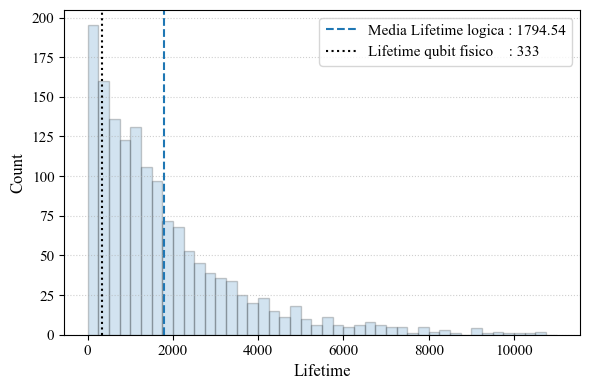

istogramma relativo a test_policy_DDQN_PPR_d5_p0.003_20251017-042142.json


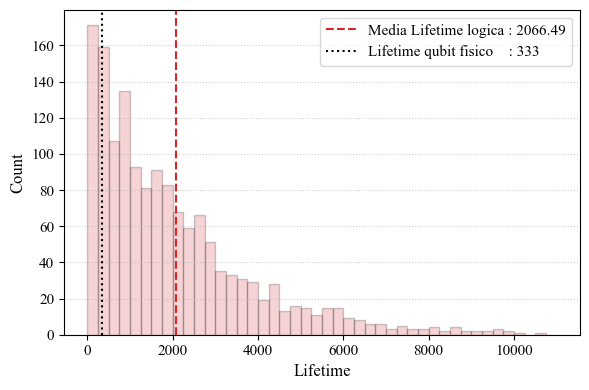

In [172]:
# istogramma
bins = np.arange(0, np.max(test_lifetimes), 250)
print(f'istogramma relativo a {test_run}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.2, color=colore_ddqn)
ax.axvline(test_avg_lifetime, c=colore_ddqn, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ddqn_p0.003.pdf', bbox_inches='tight')
plt.show()

print(f'istogramma relativo a {test_run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes_ppr, bins=bins, edgecolor='black', alpha=0.2, color=colore_ppr)
ax.axvline(test_avg_lifetime_ppr, c=colore_ppr, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime_ppr:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ppr_p0.003.pdf', bbox_inches='tight')
plt.show()


# Env X error 0.005

In [173]:
p_err = 0.005
faulty_qubit_lifetime = 1/p_err

In [174]:
run = 'DDQN_d5_p0.005_20251014-081237'
print(f'run: {run}')

run: DDQN_d5_p0.005_20251014-081237


In [175]:
# dati allenamento
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.005_20251014-081237\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime)}')


Contenuto di runs\DDQN_d5_p0.005_20251014-081237\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 557.16


In [176]:
run_ppr = 'DDQN_PPR_d5_p0.005_20251017-000003'
print(f'run: {run_ppr}')

run: DDQN_PPR_d5_p0.005_20251017-000003


In [177]:
# dati allenamento ppr
# estrazione log di allenamento 
TRAINING_LOG_PATH_ppr = r'runs\DDQN_PPR_d5_p0.005_20251017-000003\training_history.json'
training_history_ppr = load_history(TRAINING_LOG_PATH_ppr)
step_ppr = np.array([log_data['step'] for log_data in training_history_ppr])
episode_ppr = np.array([log_data['episode'] for log_data in training_history_ppr])
reward_ppr = np.array([log_data['episode_reward'] for log_data in training_history_ppr])
avg_reward_ppr  = np.array([log_data['reward_mean'] for log_data in training_history_ppr])
lifetime_ppr = np.array([log_data['episode_lifetime'] for log_data in training_history_ppr])
avg_lifetime_ppr = np.array( [log_data['lifetime_mean'] for log_data in training_history_ppr])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history_ppr])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime_ppr)}')

Contenuto di runs\DDQN_PPR_d5_p0.005_20251017-000003\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 551.28


grafico lifetime vs timestep - DDQN_d5_p0.005_20251014-081237 e DDQN_PPR_d5_p0.005_20251017-000003


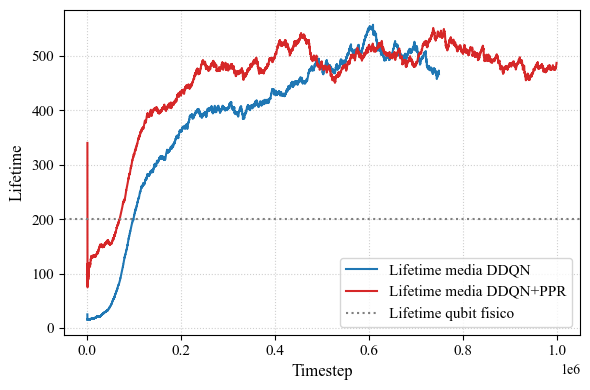

In [178]:
# avg_lifetime vs timestep
print(f'grafico lifetime vs timestep - {run} e {run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(step, avg_lifetime, c=colore_ddqn, label='Lifetime media DDQN')
ax.plot(step_ppr, avg_lifetime_ppr, c=colore_ppr, label='Lifetime media DDQN+PPR')
plt.axhline(y=faulty_qubit_lifetime, color='gray', linestyle=':', label='Lifetime qubit fisico')
ax.set_xlabel('Timestep', fontsize=12)
ax.set_ylabel('Lifetime', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('lifetime_timestep_p0.005.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafico policy riusata vs episode - DDQN_PPR_d5_p0.005_20251017-000003


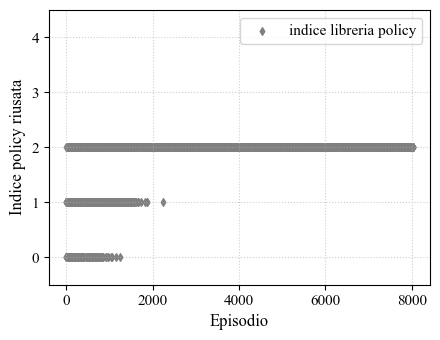

In [179]:
# reused policy vs episode
print(f'grafico policy riusata vs episode - {run_ppr}')
fig, ax = plt.subplots(figsize=(4.5,3.5))
ax.scatter(episode_ppr, index_k, c='grey', marker='d', s=15, label='indice libreria policy')
ax.set_xlabel('Episodio', fontsize=12)
ax.set_ylabel('Indice policy riusata', fontsize=12)
ax.set_yticks([ 0, 1, 2, 3, 4])
ax.set_ylim(bottom=-0.5, top=4.5)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('policy_reuse_episode_p0.005.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafici lifetime vs episodio - DDQN_d5_p0.005_20251014-081237 e DDQN_PPR_d5_p0.005_20251017-000003


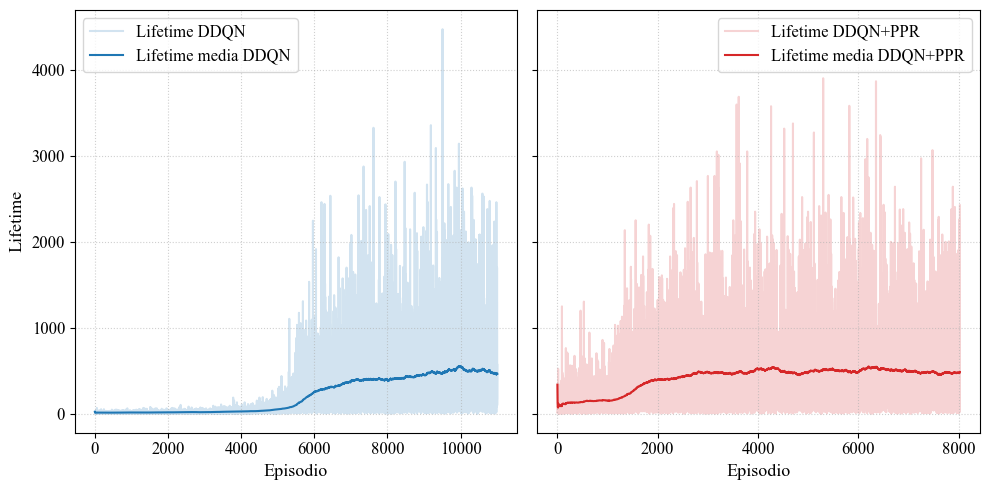

In [180]:
# lifetime vs episodio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True) 
# sharey=True assicura che entrambi gli assi Y abbiano la stessa scala 
print(f'grafici lifetime vs episodio - {run} e {run_ppr}')

ax1.plot(episode, lifetime, label='Lifetime DDQN', alpha=0.2, c=colore_ddqn, zorder=1)
ax1.plot(episode, avg_lifetime, label=f'Lifetime media DDQN', c=colore_ddqn, zorder=2) # zorder=2 per assicurare che la media sia sopra il rumore
ax1.set_xlabel('Episodio', fontsize=13)
ax1.set_ylabel('Lifetime', fontsize=13)
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.legend(fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(episode_ppr, lifetime_ppr, label='Lifetime DDQN+PPR', alpha=0.2, c=colore_ppr, zorder=1)
ax2.plot(episode_ppr, avg_lifetime_ppr, label=f'Lifetime media DDQN+PPR', c=colore_ppr, zorder=2)
ax2.set_xlabel('Episodio', fontsize=13)
ax2.tick_params(axis='both', which='major', labelsize=12)
ax2.legend(fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
# plt.savefig('lifetime_episode_p0.005.pdf', bbox_inches='tight')
plt.show()


In [181]:
# dati test
test_path = r'test_runs\test_policy_DDQN_d5_p0.005_20251014-081237.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.std(test_lifetimes)
test_run = test_path.split('\\')[1]

test_path_ppr = r'test_runs\test_policy_DDQN_PPR_d5_p0.005_20251017-000003.json'
test_history_ppr = load_history(test_path_ppr)
test_lifetimes_ppr = [log_data['lifetime'] for log_data in test_history_ppr]
test_avg_lifetime_ppr = np.mean(test_lifetimes_ppr)
test_std_lifetime_ppr = np.std(test_lifetimes_ppr)
test_run_ppr = test_path_ppr.split('\\')[1]

print(f'lifetime media ddqn     : {test_avg_lifetime}')
print(f'lifetime media ddqn+ppr : {test_avg_lifetime_ppr}')



Contenuto di test_runs\test_policy_DDQN_d5_p0.005_20251014-081237.json estratto con successo:
Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.005_20251017-000003.json estratto con successo:
lifetime media ddqn     : 652.8271428571428
lifetime media ddqn+ppr : 611.3757142857143


istogramma relativo a test_policy_DDQN_d5_p0.005_20251014-081237.json


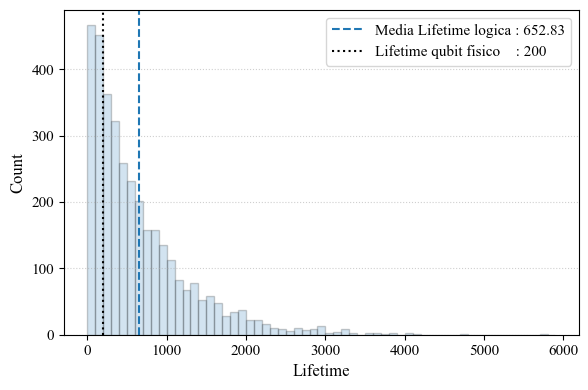

istogramma relativo a test_policy_DDQN_PPR_d5_p0.005_20251017-000003.json


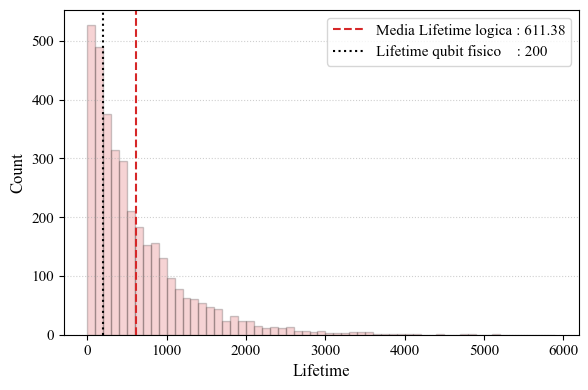

In [182]:
# istogramma
bins = np.arange(0, np.max(test_lifetimes), 100)
print(f'istogramma relativo a {test_run}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.2, color=colore_ddqn)
ax.axvline(test_avg_lifetime, c=colore_ddqn, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(fontsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ddqn_p0.005.pdf', bbox_inches='tight')
plt.show()

print(f'istogramma relativo a {test_run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes_ppr, bins=bins, edgecolor='black', alpha=0.2, color=colore_ppr)
ax.axvline(test_avg_lifetime_ppr, c=colore_ppr, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime_ppr:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(fontsize=11)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ppr_p0.005.pdf', bbox_inches='tight')
plt.show()


# Env X error 0.007

In [183]:
p_err = 0.007
faulty_qubit_lifetime = 1/p_err

In [184]:
run = 'DDQN_d5_p0.007_20251014-234730'
print(f'run: {run}')

run: DDQN_d5_p0.007_20251014-234730


In [185]:
# dati allenamento
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.007_20251014-234730\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime)}')


Contenuto di runs\DDQN_d5_p0.007_20251014-234730\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 277.01


In [186]:
run_ppr = 'DDQN_PPR_d5_p0.007_20251018-213903'
print(f'run: {run_ppr}')

run: DDQN_PPR_d5_p0.007_20251018-213903


In [187]:
# dati allenamento ppr
# estrazione log di allenamento 
TRAINING_LOG_PATH_ppr = r'runs\DDQN_PPR_d5_p0.007_20251018-213903\training_history.json'
training_history_ppr = load_history(TRAINING_LOG_PATH_ppr)
step_ppr = np.array([log_data['step'] for log_data in training_history_ppr])
episode_ppr = np.array([log_data['episode'] for log_data in training_history_ppr])
reward_ppr = np.array([log_data['episode_reward'] for log_data in training_history_ppr])
avg_reward_ppr  = np.array([log_data['reward_mean'] for log_data in training_history_ppr])
lifetime_ppr = np.array([log_data['episode_lifetime'] for log_data in training_history_ppr])
avg_lifetime_ppr = np.array( [log_data['lifetime_mean'] for log_data in training_history_ppr])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history_ppr])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime_ppr)}')

Contenuto di runs\DDQN_PPR_d5_p0.007_20251018-213903\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 268.49


grafico lifetime vs timestep - DDQN_d5_p0.007_20251014-234730 e DDQN_PPR_d5_p0.007_20251018-213903


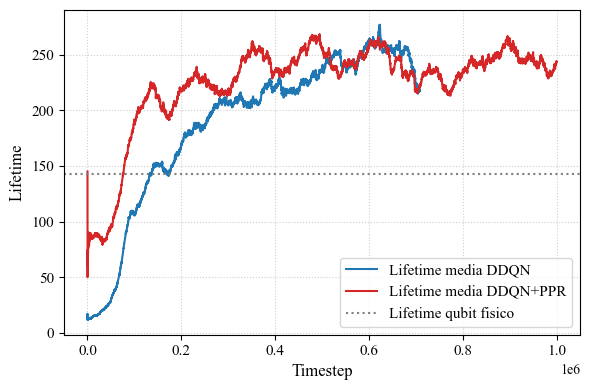

In [188]:
# avg_lifetime vs timestep
print(f'grafico lifetime vs timestep - {run} e {run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(step, avg_lifetime, c=colore_ddqn, label='Lifetime media DDQN')
ax.plot(step_ppr, avg_lifetime_ppr, c=colore_ppr, label='Lifetime media DDQN+PPR')
plt.axhline(y=faulty_qubit_lifetime, color='gray', linestyle=':', label='Lifetime qubit fisico')
ax.set_xlabel('Timestep', fontsize=12)
ax.set_ylabel('Lifetime', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('lifetime_timestep_p0.007.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafico policy riusata vs episode - DDQN_PPR_d5_p0.007_20251018-213903


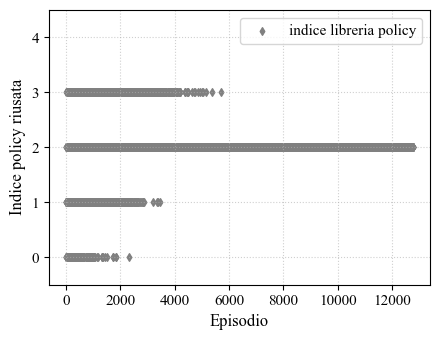

In [189]:
# reused policy vs episode
print(f'grafico policy riusata vs episode - {run_ppr}')
fig, ax = plt.subplots(figsize=(4.5,3.5))
ax.scatter(episode_ppr, index_k, c='grey', marker='d', s=15, label='indice libreria policy')
ax.set_xlabel('Episodio', fontsize=12)
ax.set_ylabel('Indice policy riusata', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.set_yticks([ 0, 1, 2, 3, 4])
ax.set_ylim(bottom=-0.5, top=4.5)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('policy_reuse_episode_p0.007.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafici lifetime vs episodio - DDQN_d5_p0.007_20251014-234730 e DDQN_PPR_d5_p0.007_20251018-213903


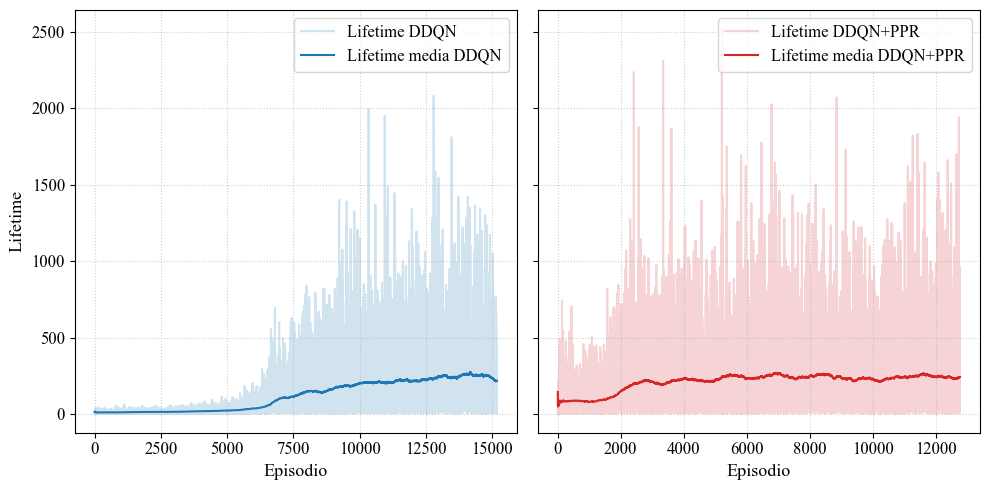

In [190]:
# lifetime vs episodio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True) 
# sharey=True assicura che entrambi gli assi Y abbiano la stessa scala 
print(f'grafici lifetime vs episodio - {run} e {run_ppr}')

ax1.plot(episode, lifetime, label='Lifetime DDQN', alpha=0.2, c=colore_ddqn, zorder=1)
ax1.plot(episode, avg_lifetime, label=f'Lifetime media DDQN', c=colore_ddqn, zorder=2) # zorder=2 per assicurare che la media sia sopra il rumore
ax1.set_xlabel('Episodio', fontsize=13)
ax1.set_ylabel('Lifetime', fontsize=13)
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.legend(fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(episode_ppr, lifetime_ppr, label='Lifetime DDQN+PPR', alpha=0.2, c=colore_ppr, zorder=1)
ax2.plot(episode_ppr, avg_lifetime_ppr, label=f'Lifetime media DDQN+PPR', c=colore_ppr, zorder=2)
ax2.set_xlabel('Episodio', fontsize=13)
ax2.tick_params(axis='both', which='major', labelsize=12)
ax2.legend(fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
# plt.savefig('lifetime_episode_p0.007.pdf', bbox_inches='tight')
plt.show()


In [191]:
# dati test
test_path = r'test_runs\test_policy_DDQN_d5_p0.007_20251014-234730.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.std(test_lifetimes)
test_run = test_path.split('\\')[1]

test_path_ppr = r'test_runs\test_policy_DDQN_PPR_d5_p0.007_20251018-213903.json'
test_history_ppr = load_history(test_path_ppr)
test_lifetimes_ppr = [log_data['lifetime'] for log_data in test_history_ppr]
test_avg_lifetime_ppr = np.mean(test_lifetimes_ppr)
test_std_lifetime_ppr = np.std(test_lifetimes_ppr)
test_run_ppr = test_path_ppr.split('\\')[1]

print(f'lifetime media ddqn     : {test_avg_lifetime}')
print(f'lifetime media ddqn+ppr : {test_avg_lifetime_ppr}')



Contenuto di test_runs\test_policy_DDQN_d5_p0.007_20251014-234730.json estratto con successo:
Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.007_20251018-213903.json estratto con successo:
lifetime media ddqn     : 340.09
lifetime media ddqn+ppr : 321.02076923076925


istogramma relativo a test_policy_DDQN_d5_p0.007_20251014-234730.json


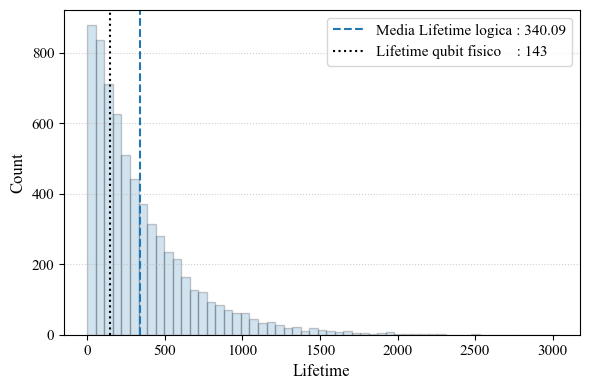

istogramma relativo a test_policy_DDQN_PPR_d5_p0.007_20251018-213903.json


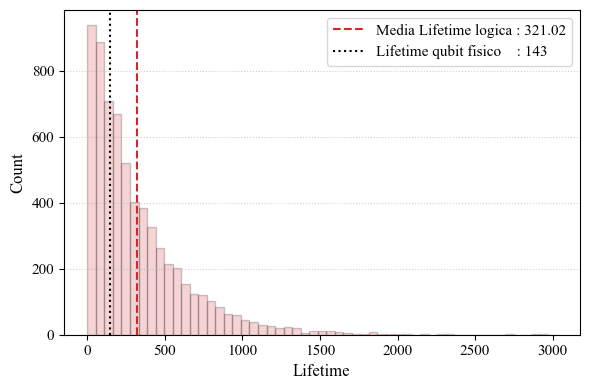

In [192]:
# istogramma
bins = np.arange(0, np.max(test_lifetimes), 55)
print(f'istogramma relativo a {test_run}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.2, color=colore_ddqn)
ax.axvline(test_avg_lifetime, c=colore_ddqn, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ddqn_p0.007.pdf', bbox_inches='tight')
plt.show()

print(f'istogramma relativo a {test_run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes_ppr, bins=bins, edgecolor='black', alpha=0.2, color=colore_ppr)
ax.axvline(test_avg_lifetime_ppr, c=colore_ppr, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime_ppr:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ppr_p0.007.pdf', bbox_inches='tight')
plt.show()


# Env X error 0.009

In [193]:
p_err = 0.009
faulty_qubit_lifetime = 1/p_err

In [194]:
run = 'DDQN_d5_p0.009_20251015-044635'
print(f'run: {run}')

run: DDQN_d5_p0.009_20251015-044635


In [195]:
# dati allenamento
# estrazione log di allenamento 
TRAINING_LOG_PATH = r'runs\DDQN_d5_p0.009_20251015-044635\training_history.json'
training_history = load_history(TRAINING_LOG_PATH)
step = np.array([log_data['step'] for log_data in training_history])
episode = np.array([log_data['episode'] for log_data in training_history])
reward = np.array([log_data['episode_reward'] for log_data in training_history])
avg_reward  = np.array([log_data['reward_mean'] for log_data in training_history])
lifetime = np.array([log_data['episode_lifetime'] for log_data in training_history])
avg_lifetime = np.array( [log_data['lifetime_mean'] for log_data in training_history])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime)}')


Contenuto di runs\DDQN_d5_p0.009_20251015-044635\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 138.69


In [196]:
run_ppr = 'DDQN_PPR_d5_p0.009_20251019-025723'
print(f'run: {run_ppr}')

run: DDQN_PPR_d5_p0.009_20251019-025723


In [197]:
# dati allenamento ppr
# estrazione log di allenamento 
TRAINING_LOG_PATH_ppr = r'runs\DDQN_PPR_d5_p0.009_20251019-025723\training_history.json'
training_history_ppr = load_history(TRAINING_LOG_PATH_ppr)
step_ppr = np.array([log_data['step'] for log_data in training_history_ppr])
episode_ppr = np.array([log_data['episode'] for log_data in training_history_ppr])
reward_ppr = np.array([log_data['episode_reward'] for log_data in training_history_ppr])
avg_reward_ppr  = np.array([log_data['reward_mean'] for log_data in training_history_ppr])
lifetime_ppr = np.array([log_data['episode_lifetime'] for log_data in training_history_ppr])
avg_lifetime_ppr = np.array( [log_data['lifetime_mean'] for log_data in training_history_ppr])
index_k = np.array([log_data['policy_index_k'] for log_data in training_history_ppr])

print(f'best avg lifetime (rolling length {rolling_average_length}) : {np.max(avg_lifetime_ppr)}')

Contenuto di runs\DDQN_PPR_d5_p0.009_20251019-025723\training_history.json estratto con successo:
best avg lifetime (rolling length 500) : 159.34


grafico lifetime vs timestep - DDQN_d5_p0.009_20251015-044635 e DDQN_PPR_d5_p0.009_20251019-025723


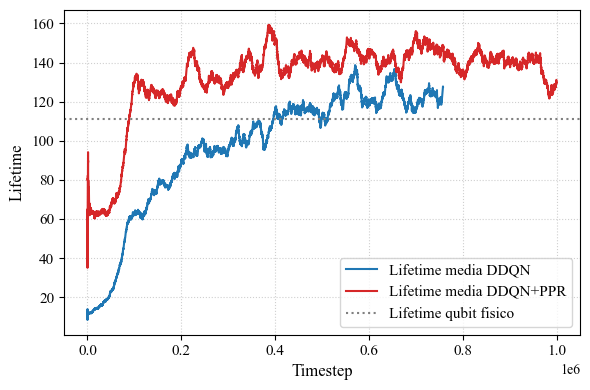

In [198]:
# avg_lifetime vs timestep
print(f'grafico lifetime vs timestep - {run} e {run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(step, avg_lifetime, c=colore_ddqn, label='Lifetime media DDQN')
ax.plot(step_ppr, avg_lifetime_ppr, c=colore_ppr, label='Lifetime media DDQN+PPR')
plt.axhline(y=faulty_qubit_lifetime, color='gray', linestyle=':', label='Lifetime qubit fisico')
ax.set_xlabel('Timestep', fontsize=12)
ax.set_ylabel('Lifetime', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('lifetime_timestep_p0.009.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafico policy riusata vs episode - DDQN_PPR_d5_p0.009_20251019-025723


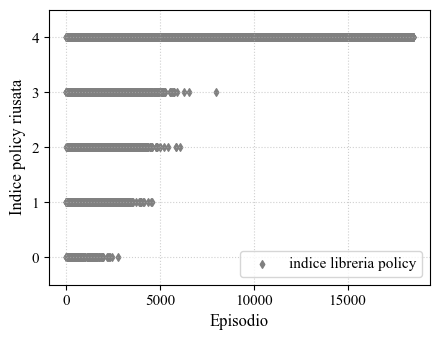

In [199]:
# reused policy vs episode
print(f'grafico policy riusata vs episode - {run_ppr}')
fig, ax = plt.subplots(figsize=(4.5,3.5))
ax.scatter(episode_ppr, index_k, c='grey', marker='d', s=15, label='indice libreria policy')
ax.set_xlabel('Episodio', fontsize=12)
ax.set_ylabel('Indice policy riusata', fontsize=12)
ax.set_yticks([ 0, 1, 2, 3, 4])
ax.set_ylim(bottom=-0.5, top=4.5)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('policy_reuse_episode_p0.009.pdf', dpi=300, bbox_inches='tight')
plt.show()


grafici lifetime vs episodio - DDQN_d5_p0.009_20251015-044635 e DDQN_PPR_d5_p0.009_20251019-025723


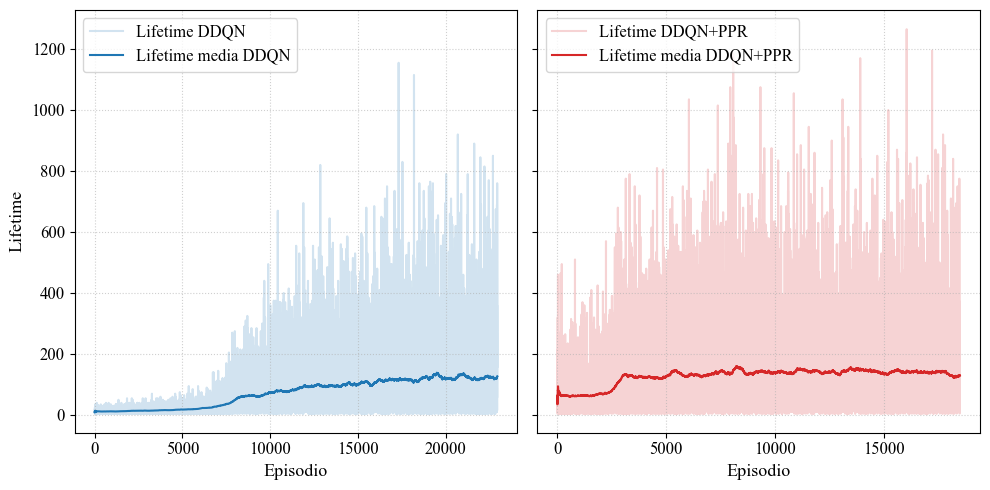

In [200]:
# lifetime vs episodio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5), sharey=True) 
# sharey=True assicura che entrambi gli assi Y abbiano la stessa scala 
print(f'grafici lifetime vs episodio - {run} e {run_ppr}')

ax1.plot(episode, lifetime, label='Lifetime DDQN', alpha=0.2, c=colore_ddqn, zorder=1)
ax1.plot(episode, avg_lifetime, label=f'Lifetime media DDQN', c=colore_ddqn, zorder=2) # zorder=2 per assicurare che la media sia sopra il rumore
ax1.set_xlabel('Episodio', fontsize=13)
ax1.set_ylabel('Lifetime', fontsize=13)
ax1.tick_params(axis='both', which='major', labelsize=12)
ax1.legend(fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(episode_ppr, lifetime_ppr, label='Lifetime DDQN+PPR', alpha=0.2, c=colore_ppr, zorder=1)
ax2.plot(episode_ppr, avg_lifetime_ppr, label=f'Lifetime media DDQN+PPR', c=colore_ppr, zorder=2)
ax2.set_xlabel('Episodio', fontsize=13)
ax2.tick_params(axis='both', which='major', labelsize=12)
ax2.legend(fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
# plt.savefig('lifetime_episode_p0.009.pdf', bbox_inches='tight')
plt.show()


In [201]:
# dati test
test_path = r'test_runs\test_policy_DDQN_d5_p0.009_20251015-044635.json'
test_history = load_history(test_path)
test_lifetimes = [log_data['lifetime'] for log_data in test_history]
test_avg_lifetime = np.mean(test_lifetimes)
test_std_lifetime = np.std(test_lifetimes)
test_run = test_path.split('\\')[1]

test_path_ppr = r'test_runs\test_policy_DDQN_PPR_d5_p0.009_20251019-025723.json'
test_history_ppr = load_history(test_path_ppr)
test_lifetimes_ppr = [log_data['lifetime'] for log_data in test_history_ppr]
test_avg_lifetime_ppr = np.mean(test_lifetimes_ppr)
test_std_lifetime_ppr = np.std(test_lifetimes_ppr)
test_run_ppr = test_path_ppr.split('\\')[1]

print(f'lifetime media ddqn     : {test_avg_lifetime}')
print(f'lifetime media ddqn+ppr : {test_avg_lifetime_ppr}')



Contenuto di test_runs\test_policy_DDQN_d5_p0.009_20251015-044635.json estratto con successo:
Contenuto di test_runs\test_policy_DDQN_PPR_d5_p0.009_20251019-025723.json estratto con successo:
lifetime media ddqn     : 162.79806451612905
lifetime media ddqn+ppr : 174.56032258064516


istogramma relativo a test_policy_DDQN_d5_p0.009_20251015-044635.json


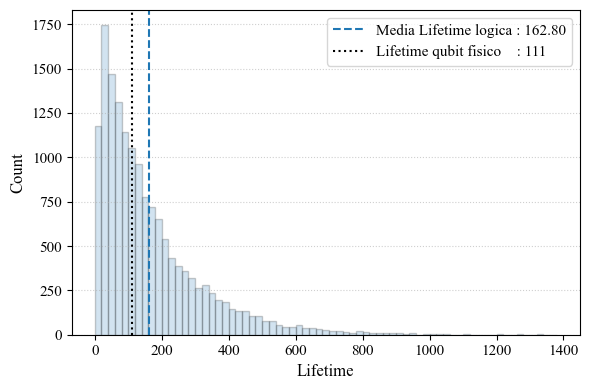

istogramma relativo a test_policy_DDQN_PPR_d5_p0.009_20251019-025723.json


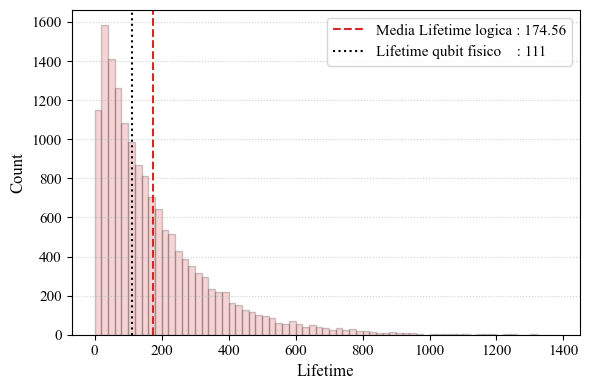

In [202]:
# istogramma
bins = np.arange(0, np.max(test_lifetimes), 20)
print(f'istogramma relativo a {test_run}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes, bins=bins, edgecolor='black', alpha=0.2, color=colore_ddqn)
ax.axvline(test_avg_lifetime, c=colore_ddqn, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ddqn_p0.009.pdf', bbox_inches='tight')
plt.show()

print(f'istogramma relativo a {test_run_ppr}')
fig, ax = plt.subplots(figsize=(6,4))
ax.hist(test_lifetimes_ppr, bins=bins, edgecolor='black', alpha=0.2, color=colore_ppr)
ax.axvline(test_avg_lifetime_ppr, c=colore_ppr, ls='dashed', lw=1.5, label=f'Media Lifetime logica : {test_avg_lifetime_ppr:.2f}')
plt.axvline(faulty_qubit_lifetime, c='0', ls=':', lw=1.5, label=f'Lifetime qubit fisico    : {faulty_qubit_lifetime:.0f}')
ax.set_xlabel('Lifetime', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
# plt.savefig('hist_test_ppr_p0.009.pdf', dpi=300, bbox_inches='tight')
plt.show()


# altro

In [203]:
# valori riassuntivi
env = np.array([0.001, 0.003, 0.005, 0.007, 0.009])
lifetime_mean_ddqn = np.array([16723, 1794, 652, 340, 162])
lifetime_mean_ppr = np.array([None, 2066, 611, 321, 174])

env_continuous = np.linspace(0.0005, 0.01, 100)
lifetime_physical_qubit = 1/env_continuous
lifetime_sc_teo = 1/env_continuous**5

Andamento lifetime vs p_err


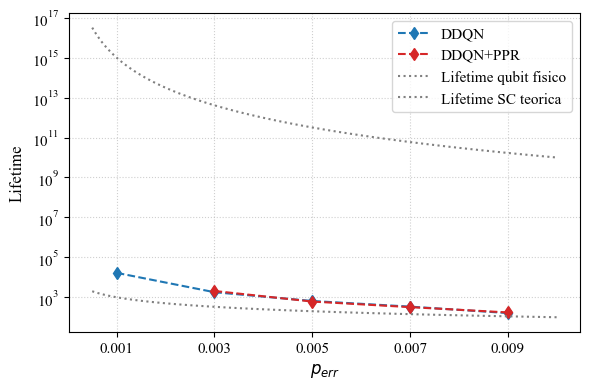

In [204]:
# reused policy vs episode
print(f'Andamento lifetime vs p_err')
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(env, lifetime_mean_ddqn, c=colore_ddqn, marker='d', markersize=6, ls='--', label='DDQN')
ax.plot(env, lifetime_mean_ppr, c=colore_ppr, marker='d', markersize=6, ls='--', label='DDQN+PPR')
ax.plot(env_continuous, lifetime_physical_qubit, c='gray', ls=':', label='Lifetime qubit fisico')
ax.plot(env_continuous, lifetime_sc_teo, c='gray', ls=':', label='Lifetime SC teorica')
ax.set_xlabel('$p_{err}$', fontsize=12)
ax.set_ylabel('Lifetime', fontsize=12)
ax.set_xticks(env)
ax.set_yscale('log')
ax.tick_params(axis='both', which='major', labelsize=11)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(fontsize=11)
plt.tight_layout()
# plt.savefig('avg_lifetimes_perr.pdf', dpi=300, bbox_inches='tight')
plt.show()
